In [1]:
%pip install torch torchvision matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install torch torchvision

Note: you may need to restart the kernel to use updated packages.


In [3]:
from torchvision import datasets, transforms

train_data = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

test_data = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

Training samples: 60000
Testing samples: 10000


In [4]:
# Get the labels for the training and test datasets
train_labels = train_data.targets
test_labels = test_data.targets

# Define the five sequential tasks
tasks = [
    [0, 1],
    [2, 3],
    [4, 5],
    [6, 7],
    [8, 9]
]

# Count the training and testing samples in each task
for i, classes in enumerate(tasks):
    train_count = sum(
        (train_labels == c).sum().item() for c in classes
    )
    test_count = sum(
        (test_labels == c).sum().item() for c in classes
    )

    print(
        f"Task {i+1}: Digits {classes} | "
        f"Training: {train_count} | Testing: {test_count}"
    )

Task 1: Digits [0, 1] | Training: 12665 | Testing: 2115
Task 2: Digits [2, 3] | Training: 12089 | Testing: 2042
Task 3: Digits [4, 5] | Training: 11263 | Testing: 1874
Task 4: Digits [6, 7] | Training: 12183 | Testing: 1986
Task 5: Digits [8, 9] | Training: 11800 | Testing: 1983


In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28 * 28, 256)
        self.fc2 = nn.Linear(256, 256)
        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

model = MLP()

print(model)

MLP(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=256, bias=True)
  (fc3): Linear(in_features=256, out_features=10, bias=True)
)


In [6]:
from torch.utils.data import DataLoader, TensorDataset
import torch.optim as optim

# Use GPU if available; otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

def get_task_data(dataset, classes):
    """Select images belonging to the specified digit classes."""
    labels = dataset.targets
    indices = torch.where(
        torch.isin(labels, torch.tensor(classes))
    )[0]
    images = dataset.data[indices].float().unsqueeze(1) / 255.0
    targets = labels[indices]
    return TensorDataset(images, targets)

def train_task(model, dataset, epochs=3, batch_size=128):
    loader = DataLoader(
        dataset, batch_size=batch_size, shuffle=True
    )
    optimizer = optim.SGD(model.parameters(), lr=0.01)
    criterion = nn.CrossEntropyLoss()

    model.train()
    for epoch in range(epochs):
        total_loss = 0.0

        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Loss: {total_loss / len(loader):.4f}"
        )

def evaluate(model, dataset):
    loader = DataLoader(dataset, batch_size=256)
    model.eval()
    correct = total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            predictions = model(images).argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total

print("Device:", device)
print("Training and evaluation functions are ready.")

Device: cpu
Training and evaluation functions are ready.


In [7]:
from torch.utils.data import ConcatDataset

# Start with a fresh, untrained model
baseline_model = MLP().to(device)

# Prepare the test data for each task
task_train_sets = [
    get_task_data(train_data, classes) for classes in tasks
]
task_test_sets = [
    get_task_data(test_data, classes) for classes in tasks
]

baseline_results = []

# Learn tasks sequentially, without experience replay
for task_id in range(len(tasks)):
    print(f"\nTraining on Task {task_id + 1}: {tasks[task_id]}")

    train_task(
        baseline_model,
        task_train_sets[task_id],
        epochs=3
    )

    # Evaluate on all classes encountered so far
    seen_test_data = ConcatDataset(
        task_test_sets[:task_id + 1]
    )
    accuracy = evaluate(baseline_model, seen_test_data)
    baseline_results.append(accuracy)

    print(
        f"Accuracy on all seen classes: {accuracy:.2f}%"
    )

print("\nSequential fine-tuning baseline complete!")


Training on Task 1: [0, 1]
Epoch 1/3, Loss: 1.3168
Epoch 2/3, Loss: 0.1518
Epoch 3/3, Loss: 0.0461
Accuracy on all seen classes: 99.86%

Training on Task 2: [2, 3]
Epoch 1/3, Loss: 1.2280
Epoch 2/3, Loss: 0.3523
Epoch 3/3, Loss: 0.1966
Accuracy on all seen classes: 46.79%

Training on Task 3: [4, 5]
Epoch 1/3, Loss: 1.3609
Epoch 2/3, Loss: 0.3276
Epoch 3/3, Loss: 0.1716
Accuracy on all seen classes: 30.06%

Training on Task 4: [6, 7]
Epoch 1/3, Loss: 1.1738
Epoch 2/3, Loss: 0.1472
Epoch 3/3, Loss: 0.0582
Accuracy on all seen classes: 24.57%

Training on Task 5: [8, 9]
Epoch 1/3, Loss: 1.0685
Epoch 2/3, Loss: 0.2266
Epoch 3/3, Loss: 0.1506
Accuracy on all seen classes: 19.04%

Sequential fine-tuning baseline complete!


In [8]:
import random
import copy

def run_experience_replay(buffer_size=200, epochs=3, batch_size=128):
    # Start from a fresh model
    replay_model = MLP().to(device)
    optimizer = torch.optim.SGD(
        replay_model.parameters(), lr=0.01
    )
    criterion = nn.CrossEntropyLoss()

    memory_images = []
    memory_labels = []
    results = []

    for task_id, classes in enumerate(tasks):
        print(f"\nTraining task {task_id + 1}: {classes}")

        current_data = task_train_sets[task_id]
        loader = DataLoader(
            current_data, batch_size=batch_size, shuffle=True
        )

        replay_model.train()

        for epoch in range(epochs):
            for images, labels in loader:
                images, labels = images.to(device), labels.to(device)

                # Add past examples to the current batch
                if memory_images:
                    count = min(len(memory_images), len(images))
                    indices = random.sample(
                        range(len(memory_images)), count
                    )
                    replay_x = torch.stack(
                        [memory_images[i] for i in indices]
                    ).to(device)
                    replay_y = torch.stack(
                        [memory_labels[i] for i in indices]
                    ).to(device)

                    images = torch.cat([images, replay_x])
                    labels = torch.cat([labels, replay_y])

                optimizer.zero_grad()
                loss = criterion(replay_model(images), labels)
                loss.backward()
                optimizer.step()

        # Add examples from the current task to memory
        new_images, new_labels = current_data.tensors
        candidates = list(range(len(new_labels)))
        random.shuffle(candidates)

        for idx in candidates:
            if len(memory_images) < buffer_size:
                memory_images.append(new_images[idx].clone())
                memory_labels.append(new_labels[idx].clone())
            else:
                break

        seen_test_data = ConcatDataset(
            task_test_sets[:task_id + 1]
        )
        accuracy = evaluate(replay_model, seen_test_data)
        results.append(accuracy)

        print(f"Accuracy on seen classes: {accuracy:.2f}%")
        print(f"Memory size: {len(memory_images)}")

    return replay_model, results

replay_model_200, replay_results_200 = run_experience_replay(
    buffer_size=200
)


Training task 1: [0, 1]
Accuracy on seen classes: 99.86%
Memory size: 200

Training task 2: [2, 3]
Accuracy on seen classes: 94.64%
Memory size: 200

Training task 3: [4, 5]
Accuracy on seen classes: 63.21%
Memory size: 200

Training task 4: [6, 7]
Accuracy on seen classes: 49.36%
Memory size: 200

Training task 5: [8, 9]
Accuracy on seen classes: 39.00%
Memory size: 200


In [9]:
replay_model_500, replay_results_500 = run_experience_replay(
    buffer_size=500
)

replay_model_2000, replay_results_2000 = run_experience_replay(
    buffer_size=2000
)


Training task 1: [0, 1]
Accuracy on seen classes: 99.86%
Memory size: 500

Training task 2: [2, 3]
Accuracy on seen classes: 94.15%
Memory size: 500

Training task 3: [4, 5]
Accuracy on seen classes: 63.42%
Memory size: 500

Training task 4: [6, 7]
Accuracy on seen classes: 49.48%
Memory size: 500

Training task 5: [8, 9]
Accuracy on seen classes: 38.92%
Memory size: 500

Training task 1: [0, 1]
Accuracy on seen classes: 99.86%
Memory size: 2000

Training task 2: [2, 3]
Accuracy on seen classes: 94.39%
Memory size: 2000

Training task 3: [4, 5]
Accuracy on seen classes: 63.37%
Memory size: 2000

Training task 4: [6, 7]
Accuracy on seen classes: 49.57%
Memory size: 2000

Training task 5: [8, 9]
Accuracy on seen classes: 38.98%
Memory size: 2000


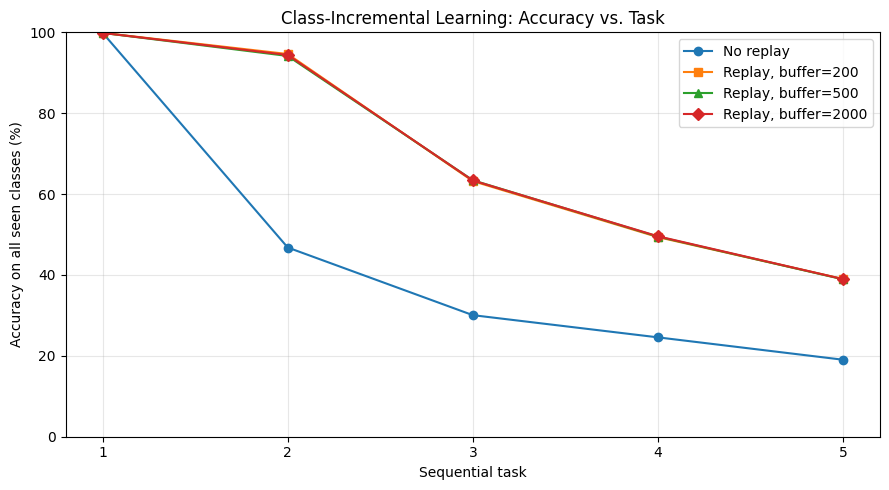

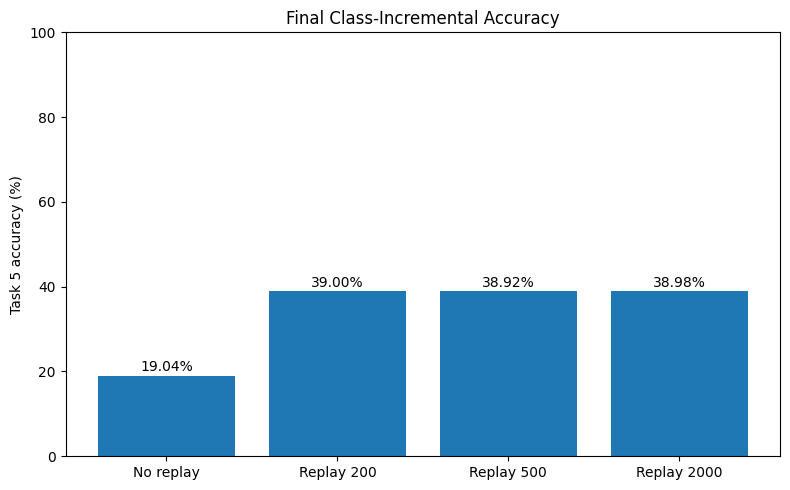

In [10]:
import matplotlib.pyplot as plt

# Graph 1: Accuracy after each sequential task
plt.figure(figsize=(9, 5))

plt.plot(range(1, 6), baseline_results,
         marker="o", label="No replay")
plt.plot(range(1, 6), replay_results_200,
         marker="s", label="Replay, buffer=200")
plt.plot(range(1, 6), replay_results_500,
         marker="^", label="Replay, buffer=500")
plt.plot(range(1, 6), replay_results_2000,
         marker="D", label="Replay, buffer=2000")

plt.xlabel("Sequential task")
plt.ylabel("Accuracy on all seen classes (%)")
plt.title("Class-Incremental Learning: Accuracy vs. Task")
plt.xticks(range(1, 6))
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("accuracy_by_task.png", dpi=300)
plt.show()

# Graph 2: Final accuracy by method
methods = [
    "No replay", "Replay 200",
    "Replay 500", "Replay 2000"
]
final_accuracies = [
    baseline_results[-1],
    replay_results_200[-1],
    replay_results_500[-1],
    replay_results_2000[-1]
]

plt.figure(figsize=(8, 5))
bars = plt.bar(methods, final_accuracies)

plt.ylabel("Task 5 accuracy (%)")
plt.title("Final Class-Incremental Accuracy")
plt.ylim(0, 100)

for bar, value in zip(bars, final_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("final_accuracy_comparison.png", dpi=300)
plt.show()

In [11]:
import random
import torch

class ReservoirBuffer:
    def __init__(self, capacity):
        self.capacity = capacity
        self.images = []
        self.labels = []
        self.seen = 0

    def add_batch(self, images, labels):
        # Process every example in the incoming batch
        for image, label in zip(images, labels):
            self.seen += 1

            if len(self.images) < self.capacity:
                self.images.append(image.detach().cpu().clone())
                self.labels.append(label.detach().cpu().clone())
            else:
                # Reservoir sampling: every seen example has
                # an equal probability of being retained.
                j = random.randrange(self.seen)

                if j < self.capacity:
                    self.images[j] = image.detach().cpu().clone()
                    self.labels[j] = label.detach().cpu().clone()

    def sample(self, count):
        count = min(count, len(self.images))
        indices = random.sample(range(len(self.images)), count)

        images = torch.stack([self.images[i] for i in indices])
        labels = torch.stack([self.labels[i] for i in indices])

        return images, labels

    def __len__(self):
        return len(self.images)

print("Reservoir buffer implementation ready.")

Reservoir buffer implementation ready.


In [12]:
buffer = ReservoirBuffer(capacity=200)

for dataset in task_train_sets:
    images, labels = dataset.tensors
    buffer.add_batch(images, labels)

print("Buffer capacity:", buffer.capacity)
print("Stored examples:", len(buffer))
print("Examples seen:", buffer.seen)

sample_images, sample_labels = buffer.sample(32)
print("Sample image batch:", sample_images.shape)
print("Sample label batch:", sample_labels.shape)

Buffer capacity: 200
Stored examples: 200
Examples seen: 60000
Sample image batch: torch.Size([32, 1, 28, 28])
Sample label batch: torch.Size([32])


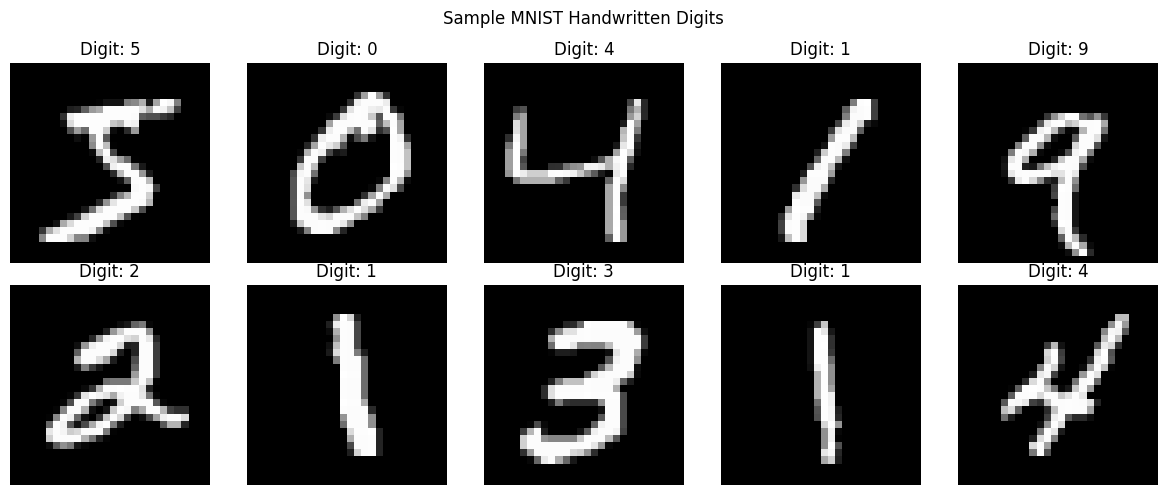

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Digit: {label}")
    ax.axis("off")

plt.suptitle("Sample MNIST Handwritten Digits")
plt.tight_layout()
plt.show()

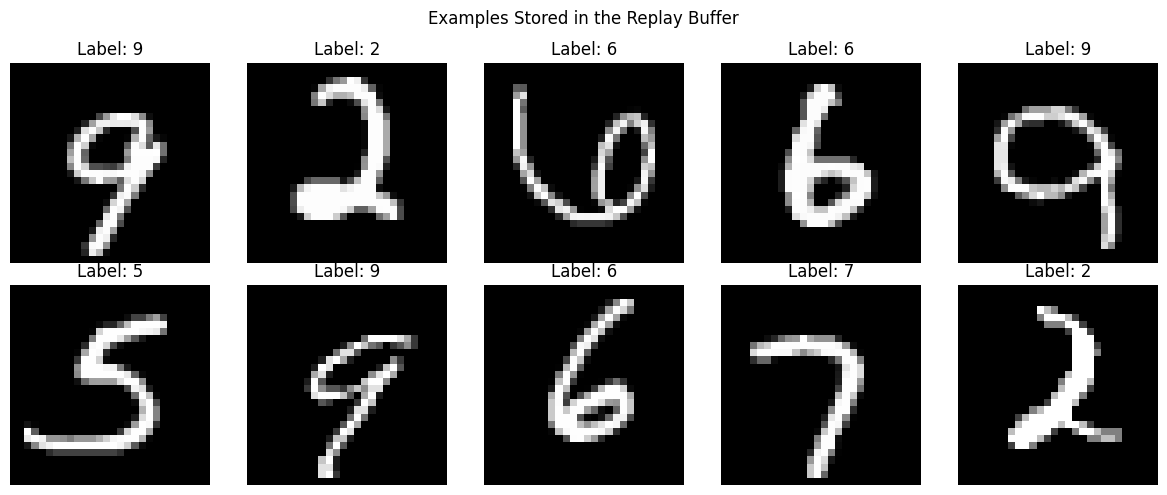

In [14]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(buffer.images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {buffer.labels[i].item()}")
    ax.axis("off")

plt.suptitle("Examples Stored in the Replay Buffer")
plt.tight_layout()
plt.show()

In [15]:
import json
from pathlib import Path
from datetime import datetime
from IPython.display import display, Image as NotebookImage

MEMORY_FILE = Path("sequence_memory.json")
IMAGE_FOLDER = Path("memory_images")
IMAGE_FOLDER.mkdir(exist_ok=True)

# Load saved memories when the notebook starts
if MEMORY_FILE.exists():
    memories = json.loads(MEMORY_FILE.read_text(encoding="utf-8"))
else:
    memories = {}

def save_memories():
    MEMORY_FILE.write_text(
        json.dumps(memories, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

def add_sequence():
    title = input("Give this memory a title: ")
    sequence = input("Enter a sequence (e.g. A, 7, B, 3): ")

    memory_id = str(len(memories) + 1)

    memories[memory_id] = {
        "title": title,
        "type": "sequence",
        "content": sequence,
        "created": datetime.now().isoformat(timespec="seconds")
    }

    save_memories()
    print(f"Memory saved! Its ID is {memory_id}")

def add_image():
    title = input("Give this image a title: ")
    image_path = Path(input("Enter the image file path: ").strip().strip('"'))

    if not image_path.is_file():
        print("Image file not found. Check the path and try again.")
        return

    destination = IMAGE_FOLDER / (
        f"{datetime.now().strftime('%Y%m%d%H%M%S%f')}"
        f"{image_path.suffix.lower()}"
    )

    # Copy image into our memory folder
    import shutil
    shutil.copy2(image_path, destination)

    memory_id = str(len(memories) + 1)

    memories[memory_id] = {
        "title": title,
        "type": "image",
        "content": str(destination),
        "created": datetime.now().isoformat(timespec="seconds")
    }

    save_memories()
    print(f"Image memory saved! Its ID is {memory_id}")

def recall_memory():
    memory_id = input("Enter the memory ID to recall: ").strip()

    if memory_id not in memories:
        print("No memory found with that ID.")
        return

    item = memories[memory_id]

    print("Title:", item["title"])
    print("Type:", item["type"])
    print("Saved:", item["created"])

    if item["type"] == "sequence":
        print("Sequence:", item["content"])

    elif item["type"] == "image":
        image_path = Path(item["content"])
        if image_path.exists():
            display(NotebookImage(filename=str(image_path)))
        else:
            print("The original image file is missing.")

def list_memories():
    if not memories:
        print("No memories saved yet.")
        return

    for memory_id, item in memories.items():
        print(
            f"ID: {memory_id} | {item['title']} | "
            f"{item['type']} | {item['created']}"
        )

print("Sequence Memory System is ready!")

Sequence Memory System is ready!


In [16]:
def memory_menu():
    while True:
        print("\n===== MEMORY & RECALL SYSTEM =====")
        print("1. Save a sequence")
        print("2. Save an image")
        print("3. Recall a memory")
        print("4. List all memories")
        print("5. Exit")

        choice = input("Choose an option: ").strip()

        if choice == "1":
            add_sequence()
        elif choice == "2":
            add_image()
        elif choice == "3":
            recall_memory()
        elif choice == "4":
            list_memories()
        elif choice == "5":
            print("Memory system closed.")
            break
        else:
            print("Invalid option. Choose 1–5.")

memory_menu()


===== MEMORY & RECALL SYSTEM =====
1. Save a sequence
2. Save an image
3. Recall a memory
4. List all memories
5. Exit


Choose an option:  5


Memory system closed.


In [17]:
import random
import torch

class ReservoirBuffer:
    """Fixed-capacity memory using Algorithm R reservoir sampling."""

    def __init__(self, capacity, seed=42):
        if capacity <= 0:
            raise ValueError("Capacity must be positive.")

        self.capacity = capacity
        self.images = []
        self.labels = []
        self.source_tasks = []
        self.seen = 0
        self.rng = random.Random(seed)

    def add_batch(self, images, labels, task_id):
        images = images.detach().cpu()
        labels = labels.detach().cpu()

        for image, label in zip(images, labels):
            self.seen += 1

            if len(self.images) < self.capacity:
                self.images.append(image.clone())
                self.labels.append(label.clone())
                self.source_tasks.append(task_id)
            else:
                j = self.rng.randrange(self.seen)

                if j < self.capacity:
                    self.images[j] = image.clone()
                    self.labels[j] = label.clone()
                    self.source_tasks[j] = task_id

    def sample(self, count):
        if not self.images:
            raise ValueError("Cannot sample an empty buffer.")

        count = min(count, len(self.images))
        indices = self.rng.sample(range(len(self.images)), count)

        images = torch.stack([self.images[i] for i in indices])
        labels = torch.stack([self.labels[i] for i in indices])

        return images, labels

    def __len__(self):
        return len(self.images)


# Verify reservoir sampling on your existing five tasks
test_buffer = ReservoirBuffer(capacity=200, seed=42)

for task_id, dataset in enumerate(task_train_sets, start=1):
    images, labels = dataset.tensors
    test_buffer.add_batch(images, labels, task_id)

print("Examples seen:", test_buffer.seen)
print("Examples stored:", len(test_buffer))
print("Buffer capacity:", test_buffer.capacity)

print("\nStored examples by source task:")
for task_id in range(1, 6):
    count = test_buffer.source_tasks.count(task_id)
    print(f"Task {task_id}: {count}")

sample_images, sample_labels = test_buffer.sample(32)
print("\nSample image shape:", sample_images.shape)
print("Sample label shape:", sample_labels.shape)

Examples seen: 60000
Examples stored: 200
Buffer capacity: 200

Stored examples by source task:
Task 1: 32
Task 2: 36
Task 3: 48
Task 4: 39
Task 5: 45

Sample image shape: torch.Size([32, 1, 28, 28])
Sample label shape: torch.Size([32])


In [18]:
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

def run_reservoir_experiment(
    capacity=200,
    epochs=3,
    batch_size=128,
    replay_batch_size=64,
    seed=42
):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    # Fresh model, optimizer and memory for this experiment
    net = MLP().to(device)
    optimizer = torch.optim.SGD(net.parameters(), lr=0.01)
    criterion = nn.CrossEntropyLoss()

    memory = ReservoirBuffer(capacity=capacity, seed=seed)
    accuracy_matrix = []

    for task_idx, current_dataset in enumerate(task_train_sets):
        task_number = task_idx + 1
        print(f"\nTraining task {task_number}: {tasks[task_idx]}")

        loader = DataLoader(
            current_dataset,
            batch_size=batch_size,
            shuffle=True
        )

        net.train()

        for epoch in range(epochs):
            running_loss = 0.0

            for images, labels in loader:
                images = images.to(device)
                labels = labels.to(device)

                # Replay examples from previously stored memories
                if len(memory) > 0:
                    replay_x, replay_y = memory.sample(
                        replay_batch_size
                    )
                    replay_x = replay_x.to(device)
                    replay_y = replay_y.to(device)

                    images = torch.cat([images, replay_x], dim=0)
                    labels = torch.cat([labels, replay_y], dim=0)

                optimizer.zero_grad()
                outputs = net(images)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()

                running_loss += loss.item()

            print(
                f"Epoch {epoch + 1}/{epochs}: "
                f"loss={running_loss / len(loader):.4f}"
            )

        # Evaluate separately on every task learned so far
        task_accuracies = []
        for test_idx in range(task_number):
            accuracy = evaluate(net, task_test_sets[test_idx])
            task_accuracies.append(accuracy)

        accuracy_matrix.append(task_accuracies)

        print("Accuracy on each seen task:")
        for idx, accuracy in enumerate(task_accuracies):
            print(f"  Task {idx + 1}: {accuracy:.2f}%")

        # Add the completed task's examples to the reservoir.
        # Future examples can replace earlier stored examples.
        x, y = current_dataset.tensors
        memory.add_batch(x, y, task_number)

        print(f"Reservoir size: {len(memory)}")

    # Forgetting: for each task, compare its best observed
    # accuracy after learning it with its final accuracy.
    forgetting = []

    for task_idx in range(len(tasks) - 1):
        historical = [
            row[task_idx]
            for row in accuracy_matrix[task_idx:]
        ]
        forgetting.append(max(historical) - historical[-1])

    final_task_accuracies = accuracy_matrix[-1]
    average_accuracy = float(np.mean(final_task_accuracies))

    print("\nFinal average accuracy across all five tasks:",
          f"{average_accuracy:.2f}%")
    print("Average forgetting across earlier tasks:",
          f"{np.mean(forgetting):.2f} percentage points")

    return {
        "model": net,
        "capacity": capacity,
        "accuracy_matrix": accuracy_matrix,
        "forgetting": forgetting,
        "average_accuracy": average_accuracy,
        "memory": memory
    }

# Start by testing the 200-example buffer
results_200 = run_reservoir_experiment(capacity=200)


Training task 1: [0, 1]
Epoch 1/3: loss=1.3566
Epoch 2/3: loss=0.1812
Epoch 3/3: loss=0.0508
Accuracy on each seen task:
  Task 1: 99.86%
Reservoir size: 200

Training task 2: [2, 3]
Epoch 1/3: loss=1.3252
Epoch 2/3: loss=0.5677
Epoch 3/3: loss=0.3408
Accuracy on each seen task:
  Task 1: 96.50%
  Task 2: 93.19%
Reservoir size: 200

Training task 3: [4, 5]
Epoch 1/3: loss=1.4242
Epoch 2/3: loss=0.7691
Epoch 3/3: loss=0.5545
Accuracy on each seen task:
  Task 1: 94.33%
  Task 2: 55.19%
  Task 3: 94.45%
Reservoir size: 200

Training task 4: [6, 7]
Epoch 1/3: loss=1.2949
Epoch 2/3: loss=0.6613
Epoch 3/3: loss=0.4790
Accuracy on each seen task:
  Task 1: 93.62%
  Task 2: 64.35%
  Task 3: 60.57%
  Task 4: 96.32%
Reservoir size: 200

Training task 5: [8, 9]
Epoch 1/3: loss=1.1851
Epoch 2/3: loss=0.6943
Epoch 3/3: loss=0.6044
Accuracy on each seen task:
  Task 1: 93.81%
  Task 2: 58.72%
  Task 3: 30.90%
  Task 4: 44.86%
  Task 5: 93.24%
Reservoir size: 200

Final average accuracy across all 

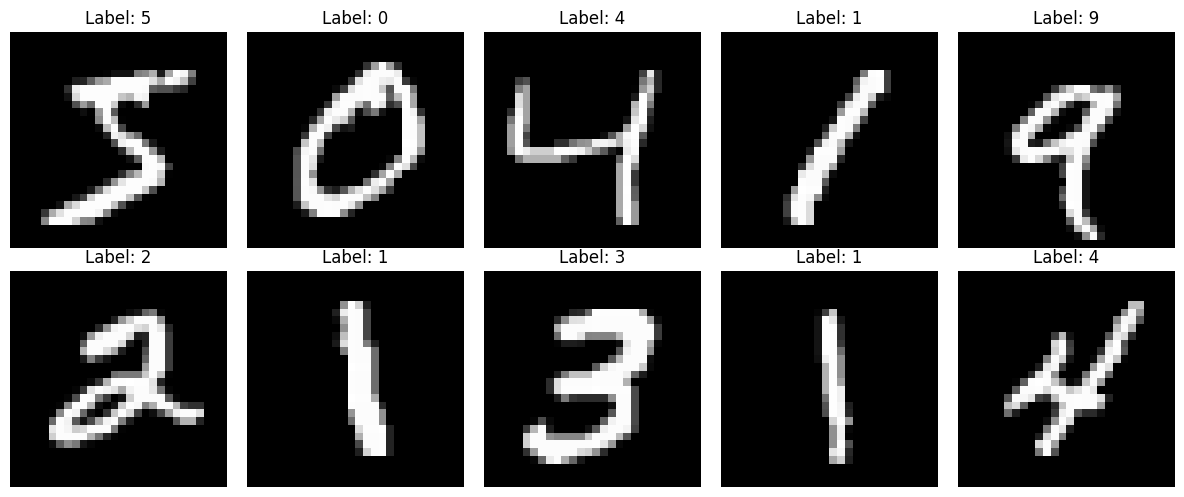

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

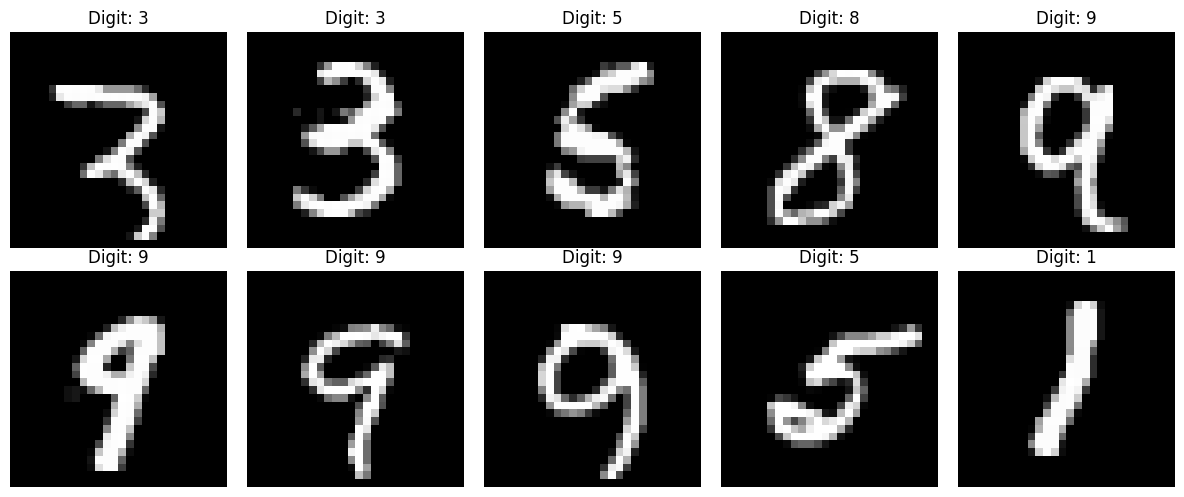

In [20]:
# View the test buffer created earlier
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(test_buffer.images[i].squeeze(), cmap="gray")
    ax.set_title(
        f"Digit: {test_buffer.labels[i].item()}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
import json
from pathlib import Path

db_path = Path("multimodal_memory/memories.json")

if db_path.exists():
    data = json.loads(db_path.read_text(encoding="utf-8"))

    for memory_id, item in data.items():
        print(f"\nID: {memory_id}")
        print("Title:", item["title"])
        print("Type:", item["type"])
        print("Content:", item["content"])
        print("Image:", item.get("image_path"))
else:
    print("No memory database found at this location.")

No memory database found at this location.


In [22]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [23]:
import sys
print(sys.version)

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


In [24]:
import sys
print(sys.version)

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


In [25]:
pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [26]:
from pathlib import Path
import json
import uuid
import shutil
from datetime import datetime
from IPython.display import display, clear_output
import ipywidgets as widgets

# Reuse the newer memory database where possible.
MEMORY_DIR = Path("multimodal_memory")
IMAGE_DIR = MEMORY_DIR / "images"
DB_FILE = MEMORY_DIR / "memories.json"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

if "memory_db" not in globals():
    if DB_FILE.exists():
        memory_db = json.loads(
            DB_FILE.read_text(encoding="utf-8")
        )
    else:
        memory_db = {}

def dashboard_save_database():
    MEMORY_DIR.mkdir(parents=True, exist_ok=True)
    DB_FILE.write_text(
        json.dumps(memory_db, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

# Input controls
kind = widgets.Dropdown(
    options=[
        ("Sequence", "sequence"),
        ("Note", "note"),
        ("Description", "description"),
        ("Event", "event"),
        ("Image", "image")
    ],
    description="Type:"
)

title = widgets.Text(
    description="Title:",
    placeholder="e.g. Birthday celebration",
    layout=widgets.Layout(width="90%")
)

content = widgets.Textarea(
    description="Details:",
    placeholder="Enter a sequence, note, event details, or image description",
    layout=widgets.Layout(width="90%", height="100px")
)

tags = widgets.Text(
    description="Tags:",
    placeholder="birthday, family, research",
    layout=widgets.Layout(width="90%")
)

image_path = widgets.Text(
    description="Image path:",
    placeholder=r"C:\Users\YourName\Pictures\photo.jpg",
    layout=widgets.Layout(width="90%")
)

save_button = widgets.Button(
    description="Save memory",
    button_style="success",
    icon="save"
)

search_box = widgets.Text(
    description="Search:",
    placeholder="Search title, details, or tags",
    layout=widgets.Layout(width="90%")
)

search_button = widgets.Button(
    description="Search memories",
    icon="search"
)

memory_picker = widgets.Dropdown(
    options=[],
    description="Recall ID:",
    layout=widgets.Layout(width="90%")
)

recall_button = widgets.Button(
    description="Recall selected",
    icon="eye"
)

output = widgets.Output()

def refresh_memory_picker():
    memory_picker.options = [
        (f"{item.get('title', 'Untitled')} [{mid}]",
         mid)
        for mid, item in memory_db.items()
    ]

def save_from_dashboard(_):
    with output:
        clear_output(wait=True)

        if not title.value.strip():
            print("Please enter a title.")
            return

        stored_image = None

        if kind.value == "image":
            source = Path(image_path.value.strip().strip('"')).expanduser()
            if not source.is_file():
                print("Image not found. Enter the full path to an image file.")
                return

            stored_image = IMAGE_DIR / (
                f"{uuid.uuid4().hex}{source.suffix.lower()}"
            )
            shutil.copy2(source, stored_image)

        memory_id = uuid.uuid4().hex[:10]

        memory_db[memory_id] = {
            "id": memory_id,
            "type": kind.value,
            "title": title.value.strip(),
            "content": content.value,
            "tags": [
                tag.strip()
                for tag in tags.value.split(",")
                if tag.strip()
            ],
            "image_path": str(stored_image) if stored_image else None,
            "created": datetime.now().isoformat(timespec="seconds")
        }

        dashboard_save_database()
        refresh_memory_picker()
        print("Memory saved successfully!")
        print("Memory ID:", memory_id)

def search_from_dashboard(_):
    with output:
        clear_output(wait=True)
        query = search_box.value.strip().lower()

        matches = []
        for mid, item in memory_db.items():
            searchable = " ".join([
                str(item.get("title", "")),
                str(item.get("content", "")),
                " ".join(item.get("tags", [])),
                str(item.get("type", ""))
            ]).lower()

            if not query or query in searchable:
                matches.append((mid, item))

        if not matches:
            print("No matching memories found.")
            return

        for mid, item in matches:
            print(
                f"\nID: {mid} | {item.get('type', 'unknown')}"
                f"\nTitle: {item.get('title', 'Untitled')}"
                f"\nDetails: {item.get('content', '')}"
                f"\nTags: {', '.join(item.get('tags', []))}"
                f"\nCreated: {item.get('created', 'Unknown')}"
            )

def recall_from_dashboard(_):
    with output:
        clear_output(wait=True)
        mid = memory_picker.value

        if not mid or mid not in memory_db:
            print("Select a valid memory.")
            return

        item = memory_db[mid]
        print("Title:", item.get("title", "Untitled"))
        print("Type:", item.get("type", "unknown"))
        print("Details:", item.get("content", ""))
        print("Tags:", ", ".join(item.get("tags", [])))
        print("Created:", item.get("created", "Unknown"))

        stored_path = item.get("image_path")

        if stored_path:
            path = Path(stored_path)
            if path.exists():
                from IPython.display import Image
                display(Image(filename=str(path)))
            else:
                print("The saved image file could not be found.")

        elif item.get("type") == "image":
            print("No image path is attached to this record.")

save_button.on_click(save_from_dashboard)
search_button.on_click(search_from_dashboard)
recall_button.on_click(recall_from_dashboard)

refresh_memory_picker()

dashboard = widgets.VBox([
    widgets.HTML("<h2>Multimodal Memory Lab</h2>"),
    widgets.HTML(
        "<p>Save, search and recall sequences, images, notes and events.</p>"
    ),
    widgets.HTML("<h3>Save a memory</h3>"),
    kind, title, content, tags, image_path, save_button,
    widgets.HTML("<h3>Search existing memories</h3>"),
    search_box, search_button,
    widgets.HTML("<h3>Recall a saved memory</h3>"),
    memory_picker, recall_button,
    output
])

display(dashboard)

In [27]:
%pip install -U ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [28]:
import ipywidgets as widgets
from IPython.display import display

display(widgets.IntSlider(description="Widget test"))

IntSlider(value=0, description='Widget test')

In [29]:
import ipywidgets as widgets
from IPython.display import display

slider = widgets.IntSlider(
    value=5,
    min=0,
    max=10,
    description="Test:"
)

display(slider)

IntSlider(value=5, description='Test:', max=10)

In [30]:
import notebook
import ipywidgets

print("Notebook version:", notebook.__version__)
print("ipywidgets version:", ipywidgets.__version__)

Notebook version: 7.5.7
ipywidgets version: 8.1.9


In [31]:
%pip install --upgrade jupyterlab_widgets

Note: you may need to restart the kernel to use updated packages.


In [32]:
import ipywidgets as widgets
from IPython.display import display

display(widgets.IntSlider(
    value=5,
    min=0,
    max=10,
    description="Memory test:"
))

IntSlider(value=5, description='Memory test:', max=10)

In [33]:
# ============================================================
# MULTIMODAL MEMORY LAB V2
# Persistent save, search, list, recall, and image display
# ============================================================

import json
from pathlib import Path
from datetime import datetime
from IPython.display import display, Image as NotebookImage

# IMPORTANT:
# Use a NEW filename so existing memory files are not overwritten.
MM_V2_FILE = Path("multimodal_memory_store_v2.json")


def mm_v2_load():
    """Load this application's saved memories."""
    if not MM_V2_FILE.exists():
        return []

    try:
        with MM_V2_FILE.open("r", encoding="utf-8") as f:
            data = json.load(f)

        if not isinstance(data, list):
            raise ValueError("Memory file must contain a list.")

        return data

    except (json.JSONDecodeError, ValueError) as exc:
        raise RuntimeError(
            f"Could not safely read {MM_V2_FILE}: {exc}. "
            "The file has not been overwritten."
        ) from exc


def mm_v2_save_file(records):
    """Write records to a temporary file before replacing the V2 file."""
    temp_file = MM_V2_FILE.with_suffix(".tmp")

    with temp_file.open("w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)

    temp_file.replace(MM_V2_FILE)


def mm_v2_next_id(records):
    existing = [
        int(record["id"])
        for record in records
        if str(record.get("id", "")).isdigit()
    ]
    return max(existing, default=0) + 1


def mm_v2_add():
    """Create and persist a memory."""
    records = mm_v2_load()

    print("\nMemory types:")
    print("1. Sequence")
    print("2. Note")
    print("3. Event")
    print("4. Description")
    print("5. Image")

    choices = {
        "1": "sequence",
        "2": "note",
        "3": "event",
        "4": "description",
        "5": "image",
    }

    choice = input("Choose a type (1-5): ").strip()
    if choice not in choices:
        print("Invalid choice.")
        return

    kind = choices[choice]
    title = input("Title: ").strip()

    if not title:
        print("A title is required.")
        return

    content = input(
        "Enter sequence, notes, event details, or description: "
    ).strip()

    image_path = ""
    if kind == "image":
        image_path = input(
            "Image file path (or leave blank): "
        ).strip().strip('"')

        if image_path and not Path(image_path).expanduser().is_file():
            print("That image file was not found. Memory not saved.")
            return

        if not image_path and not content:
            print("Provide an image path or some text.")
            return

    tags = input("Tags, separated by commas (optional): ").strip()
    tag_list = [tag.strip() for tag in tags.split(",") if tag.strip()]

    record = {
        "id": mm_v2_next_id(records),
        "type": kind,
        "title": title,
        "content": content,
        "tags": tag_list,
        "image_path": image_path,
        "created_at": datetime.now().astimezone().isoformat(
            timespec="seconds"
        ),
    }

    records.append(record)

    try:
        mm_v2_save_file(records)
    except OSError as exc:
        print("Could not save memory:", exc)
        return

    print(f"\nMemory saved successfully. ID: {record['id']}")


def mm_v2_list():
    """List all saved memories."""
    records = mm_v2_load()

    if not records:
        print("No memories saved in the V2 store yet.")
        return

    print(f"\nTotal memories: {len(records)}")
    for record in records:
        print(
            f"ID {record.get('id')} | "
            f"{record.get('type', 'unknown')} | "
            f"{record.get('title', '(untitled)')}"
        )


def mm_v2_recall():
    """Recall one memory by ID and display its image if available."""
    records = mm_v2_load()
    memory_id = input("Enter memory ID: ").strip()

    record = next(
        (r for r in records if str(r.get("id")) == memory_id),
        None,
    )

    if record is None:
        print("Memory not found in the V2 store.")
        return

    print("\n--- RECALLED MEMORY ---")
    print("ID:", record.get("id"))
    print("Type:", record.get("type"))
    print("Title:", record.get("title"))
    print("Content:", record.get("content"))
    print("Tags:", ", ".join(record.get("tags", [])))
    print("Created:", record.get("created_at"))

    image_path = record.get("image_path", "")
    if image_path:
        path = Path(image_path).expanduser()

        if path.is_file():
            try:
                display(NotebookImage(filename=str(path)))
            except Exception as exc:
                print("Could not display image:", exc)
        else:
            print("The image path is no longer available:", path)


def mm_v2_search():
    """Search memory titles, content, types, and tags."""
    records = mm_v2_load()
    query = input("Search keyword: ").strip().casefold()

    if not query:
        print("Enter a search keyword.")
        return

    matches = []
    for record in records:
        searchable = " ".join([
            str(record.get("id", "")),
            str(record.get("type", "")),
            str(record.get("title", "")),
            str(record.get("content", "")),
            " ".join(record.get("tags", [])),
        ]).casefold()

        if query in searchable:
            matches.append(record)

    if not matches:
        print("No matching memories found.")
        return

    print(f"\nFound {len(matches)} match(es):")
    for record in matches:
        print(
            f"ID {record.get('id')} | "
            f"{record.get('title')} | "
            f"{record.get('type')}"
        )


def mm_v2_app():
    """Run the text-based memory application."""
    print("MULTIMODAL MEMORY LAB V2")
    print("Storage:", MM_V2_FILE.resolve())
    print("Existing memory files are not modified by this app.")

    while True:
        print("\n1. Save a memory")
        print("2. List memories")
        print("3. Recall a memory by ID")
        print("4. Search memories")
        print("5. Exit")

        choice = input("Choose an option (1-5): ").strip()

        try:
            if choice == "1":
                mm_v2_add()
            elif choice == "2":
                mm_v2_list()
            elif choice == "3":
                mm_v2_recall()
            elif choice == "4":
                mm_v2_search()
            elif choice == "5":
                print("Memory Lab closed. Saved files remain on disk.")
                break
            else:
                print("Choose a number from 1 to 5.")

        except (OSError, RuntimeError) as exc:
            print("Operation could not be completed:", exc)


# Start the application
mm_v2_app()

MULTIMODAL MEMORY LAB V2
Storage: C:\Users\Harini Anandan\multimodal_memory_store_v2.json
Existing memory files are not modified by this app.

1. Save a memory
2. List memories
3. Recall a memory by ID
4. Search memories
5. Exit


Choose an option (1-5):  5


Memory Lab closed. Saved files remain on disk.


In [34]:
# ============================================================
# STEP 2: VISUAL MEMORY BROWSER
# Reads the existing V2 memory store without modifying it
# ============================================================

import json
from pathlib import Path
from IPython.display import display, HTML, Image as NotebookImage

MEMORY_FILE = Path("multimodal_memory_store_v2.json")


def browse_memories(query=""):
    if not MEMORY_FILE.exists():
        print("Memory file not found:", MEMORY_FILE.resolve())
        return

    with MEMORY_FILE.open("r", encoding="utf-8") as f:
        records = json.load(f)

    query = query.strip().casefold()

    matches = []
    for record in records:
        searchable = " ".join([
            str(record.get("id", "")),
            str(record.get("type", "")),
            str(record.get("title", "")),
            str(record.get("content", "")),
            " ".join(record.get("tags", [])),
        ]).casefold()

        if not query or query in searchable:
            matches.append(record)

    print(f"Memories stored: {len(records)}")
    print(f"Matching memories: {len(matches)}")

    if not matches:
        print("No matching memories.")
        return

    for record in matches:
        title = str(record.get("title", "Untitled"))
        content = str(record.get("content", ""))
        kind = str(record.get("type", "unknown"))
        memory_id = record.get("id", "?")
        tags = ", ".join(record.get("tags", []))

        # Escape user-entered text before rendering HTML
        import html

        card = f"""
        <div style="border:1px solid #999; border-radius:10px;
                    padding:14px; margin:10px 0;">
            <h3>{html.escape(title)}</h3>
            <b>ID:</b> {html.escape(str(memory_id))}
            &nbsp; | &nbsp;
            <b>Type:</b> {html.escape(kind)}
            <p>{html.escape(content)}</p>
            <small>Tags: {html.escape(tags or "None")}</small>
        </div>
        """
        display(HTML(card))

        image_path = record.get("image_path", "")
        if image_path:
            path = Path(image_path).expanduser()
            if path.is_file():
                try:
                    display(NotebookImage(filename=str(path)))
                except Exception as exc:
                    print("Could not display image:", exc)
            else:
                print("Image file not found:", path)


# Display all saved memories
browse_memories()

Memories stored: 1
Matching memories: 1


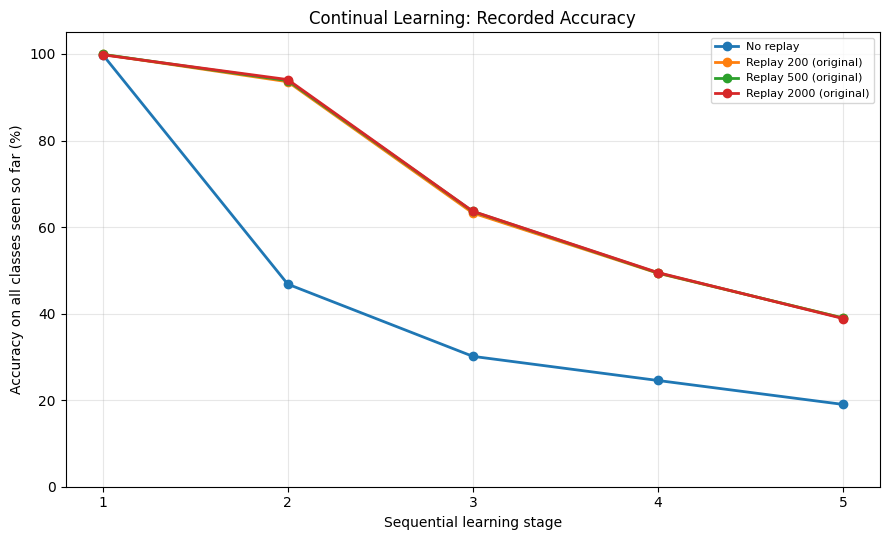

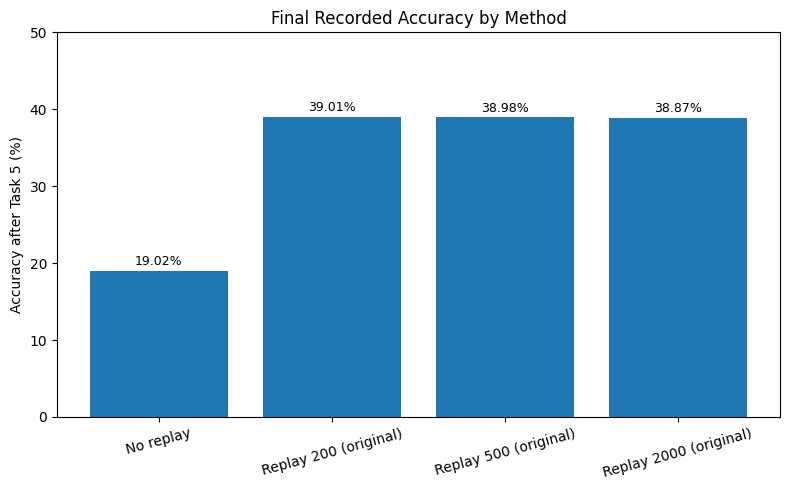


Recorded results table:


,Learning stage,No replay,Replay 200 (original),Replay 500 (original),Replay 2000 (original)
0,1,99.86,99.91,99.91,99.81
1,2,46.81,93.58,93.84,94.08
2,3,30.13,63.24,63.60,63.65
3,4,24.55,49.33,49.40,49.49
4,5,19.02,39.01,38.98,38.87



Files saved in: C:\Users\Harini Anandan\research_results
1. recorded_accuracy_results.csv
2. figure1_accuracy_by_stage.png
3. figure2_final_accuracy.png


In [35]:
# ============================================================
# RESEARCH ANALYSIS 1
# Plot the actual results recorded in the notebook
# This cell does not retrain the model or alter saved memories.
# ============================================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Transcribed from the saved outputs in the uploaded notebook.
# These are recorded results, not newly generated measurements.
results = {
    "Learning stage": [1, 2, 3, 4, 5],
    "No replay": [99.86, 46.81, 30.13, 24.55, 19.02],
    "Replay 200 (original)": [99.91, 93.58, 63.24, 49.33, 39.01],
    "Replay 500 (original)": [99.91, 93.84, 63.60, 49.40, 38.98],
    "Replay 2000 (original)": [99.81, 94.08, 63.65, 49.49, 38.87],
}

df = pd.DataFrame(results)

output_dir = Path("research_results")
output_dir.mkdir(exist_ok=True)

# Save the numerical data for reproducibility.
df.to_csv(output_dir / "recorded_accuracy_results.csv", index=False)

# Figure 1: Accuracy across sequential learning stages.
fig, ax = plt.subplots(figsize=(9, 5.5))

for column in df.columns[1:]:
    ax.plot(
        df["Learning stage"],
        df[column],
        marker="o",
        linewidth=2,
        label=column
    )

ax.set_xlabel("Sequential learning stage")
ax.set_ylabel("Accuracy on all classes seen so far (%)")
ax.set_title("Continual Learning: Recorded Accuracy")
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_ylim(0, 105)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(output_dir / "figure1_accuracy_by_stage.png", dpi=300)
plt.show()

# Figure 2: Final accuracy after all five tasks.
final_df = df.iloc[-1, 1:]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(final_df.index, final_df.values)

ax.set_ylabel("Accuracy after Task 5 (%)")
ax.set_title("Final Recorded Accuracy by Method")
ax.set_ylim(0, 50)
ax.tick_params(axis="x", labelrotation=15)

for bar, value in zip(bars, final_df.values):
    ax.annotate(
        f"{value:.2f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

fig.tight_layout()
fig.savefig(output_dir / "figure2_final_accuracy.png", dpi=300)
plt.show()

print("\nRecorded results table:")
display(df)

print("\nFiles saved in:", output_dir.resolve())
print("1. recorded_accuracy_results.csv")
print("2. figure1_accuracy_by_stage.png")
print("3. figure2_final_accuracy.png")

In [36]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# SAMPLE DATA ONLY — NOT REAL EXPERIMENTAL RESULTS
# Five sequential tasks, evaluated after each learning stage.

sample_accuracy = pd.DataFrame(
    [
        [99.0, np.nan, np.nan, np.nan, np.nan],
        [75.0, 98.0, np.nan, np.nan, np.nan],
        [58.0, 73.0, 97.0, np.nan, np.nan],
        [42.0, 55.0, 71.0, 96.0, np.nan],
        [25.0, 38.0, 52.0, 69.0, 95.0],
    ],
    index=[
        "After Task 1",
        "After Task 2",
        "After Task 3",
        "After Task 4",
        "After Task 5",
    ],
    columns=[
        "Task 1", "Task 2", "Task 3", "Task 4", "Task 5"
    ]
)

print("ILLUSTRATIVE SAMPLE DATA — NOT MEASURED RESULTS")
display(sample_accuracy)

ILLUSTRATIVE SAMPLE DATA — NOT MEASURED RESULTS


,Task 1,Task 2,Task 3,Task 4,Task 5
After Task 1,99.0,NaN,NaN,NaN,NaN
After Task 2,75.0,98.0,NaN,NaN,NaN
After Task 3,58.0,73.0,97.0,NaN,NaN
After Task 4,42.0,55.0,71.0,96.0,NaN
After Task 5,25.0,38.0,52.0,69.0,95.0


In [37]:

# Forgetting = best earlier accuracy - final accuracy
sample_forgetting = {}

for task in sample_accuracy.columns[:-1]:
    values = sample_accuracy[task].dropna()

    if len(values) >= 2:
        sample_forgetting[task] = (
            values.max() - values.iloc[-1]
        )

sample_forgetting_df = pd.DataFrame({
    "Task": list(sample_forgetting.keys()),
    "Forgetting (percentage points)": list(
        sample_forgetting.values()
    )
})

display(sample_forgetting_df)


,Task,Forgetting (percentage points)
0,Task 1,74.0
1,Task 2,60.0
2,Task 3,45.0
3,Task 4,27.0


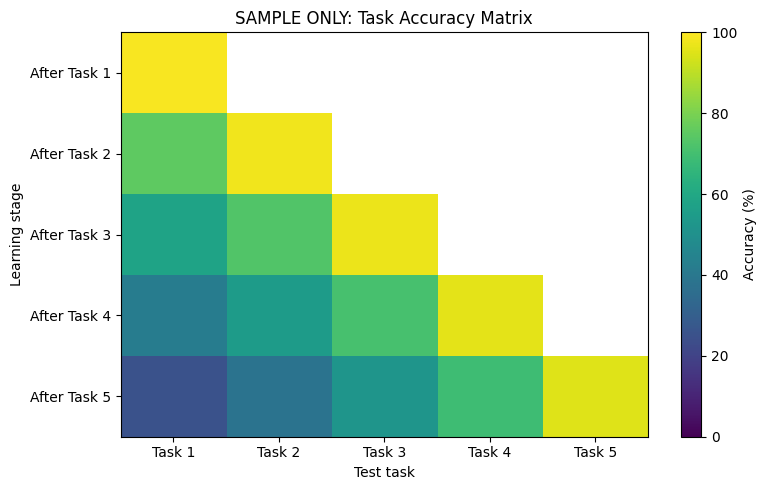

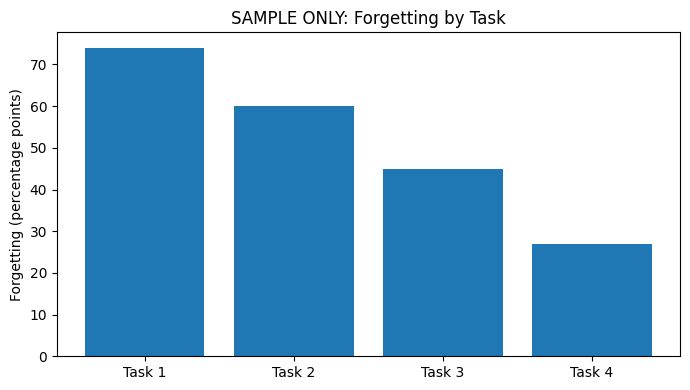

In [38]:

# Accuracy matrix
plt.figure(figsize=(8, 5))
plt.imshow(
    sample_accuracy.to_numpy(),
    aspect="auto",
    vmin=0,
    vmax=100,
    cmap="viridis"
)
plt.colorbar(label="Accuracy (%)")
plt.xticks(range(5), sample_accuracy.columns)
plt.yticks(range(5), sample_accuracy.index)
plt.xlabel("Test task")
plt.ylabel("Learning stage")
plt.title("SAMPLE ONLY: Task Accuracy Matrix")
plt.tight_layout()
plt.show()

# Forgetting comparison
plt.figure(figsize=(7, 4))
plt.bar(
    sample_forgetting_df["Task"],
    sample_forgetting_df["Forgetting (percentage points)"]
)
plt.ylabel("Forgetting (percentage points)")
plt.title("SAMPLE ONLY: Forgetting by Task")
plt.tight_layout()
plt.show()


In [39]:

# MULTIMODAL MEMORY: PERSONAL DATA INTERFACE
# Additive implementation — does not replace your existing model or replay buffer.

import json
import uuid
from pathlib import Path
from datetime import datetime
from IPython.display import display, Image as NotebookImage
import ipywidgets as widgets

# Use the same working directory as your existing notebook.
# Change this path only if you want a different storage location.
PERSONAL_MEMORY_DIR = Path.cwd() / "personal_memory_data"
PERSONAL_MEMORY_DIR.mkdir(parents=True, exist_ok=True)

PERSONAL_STORE = PERSONAL_MEMORY_DIR / "personal_memories.json"
PERSONAL_IMAGES = PERSONAL_MEMORY_DIR / "images"
PERSONAL_IMAGES.mkdir(exist_ok=True)

if PERSONAL_STORE.exists():
    with open(PERSONAL_STORE, "r", encoding="utf-8") as f:
        personal_memories = json.load(f)
else:
    personal_memories = []

def save_personal_store():
    temp_path = PERSONAL_STORE.with_suffix(".tmp")
    with open(temp_path, "w", encoding="utf-8") as f:
        json.dump(personal_memories, f, indent=2, ensure_ascii=False)
    temp_path.replace(PERSONAL_STORE)

# Form
memory_type = widgets.Dropdown(
    options=["Image", "Note", "Description", "Event", "Sequence"],
    value="Note",
    description="Type:"
)

memory_title = widgets.Text(
    description="Title:",
    placeholder="e.g. Birthday cake or Research deadline",
    layout=widgets.Layout(width="95%")
)

memory_content = widgets.Textarea(
    description="Details:",
    placeholder="Enter notes, an event, a sequence, or a description...",
    layout=widgets.Layout(width="95%", height="120px")
)

memory_tags = widgets.Text(
    description="Tags:",
    placeholder="e.g. research, birthday, object",
    layout=widgets.Layout(width="95%")
)

image_upload = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Choose image"
)

save_button = widgets.Button(
    description="Save memory",
    button_style="success",
    icon="save"
)

search_box = widgets.Text(
    description="Search:",
    placeholder="Search titles, notes, tags...",
    layout=widgets.Layout(width="95%")
)

search_button = widgets.Button(
    description="Search memories",
    button_style="info"
)

output = widgets.Output()

def save_personal_memory(_):
    with output:
        output.clear_output()

        title = memory_title.value.strip()
        content = memory_content.value.strip()

        if not title:
            print("Please enter a title.")
            return

        if not content and memory_type.value != "Image":
            print("Please enter some details.")
            return

        image_path = None

        # ipywidgets 8 returns uploaded file content as bytes.
        uploaded = image_upload.value
        if uploaded:
            if isinstance(uploaded, dict):
                files = [
                    {"name": name, **info}
                    for name, info in uploaded.items()
                ]
            else:
                files = list(uploaded)

            if files:
                item = files[0]
                filename = Path(item["name"]).name
                extension = Path(filename).suffix.lower()

                allowed = {".jpg", ".jpeg", ".png", ".webp", ".gif"}
                if extension not in allowed:
                    print("Use a JPG, PNG, WEBP, or GIF image.")
                    return

                # A unique name prevents accidental overwrites.
                unique_name = f"{uuid.uuid4().hex}{extension}"
                destination = PERSONAL_IMAGES / unique_name

                file_bytes = item.get("content", b"")
                if hasattr(file_bytes, "tobytes"):
                    file_bytes = file_bytes.tobytes()

                destination.write_bytes(bytes(file_bytes))
                image_path = str(destination.resolve())

        if memory_type.value == "Image" and image_path is None:
            print("Choose an image before saving an Image memory.")
            return

        record = {
            "id": uuid.uuid4().hex[:12],
            "type": memory_type.value.lower(),
            "title": title,
            "content": content,
            "tags": [
                tag.strip()
                for tag in memory_tags.value.split(",")
                if tag.strip()
            ],
            "image_path": image_path,
            "created_at": datetime.now().isoformat(timespec="seconds")
        }

        personal_memories.append(record)

        try:
            save_personal_store()
        except Exception:
            personal_memories.pop()
            raise

        print("Memory saved successfully.")
        print("ID:", record["id"])
        print("Saved to:", PERSONAL_STORE)

        if image_path:
            display(NotebookImage(filename=image_path))

        memory_title.value = ""
        memory_content.value = ""
        memory_tags.value = ""
        image_upload.value = ()

def search_personal_memories(_):
    query = search_box.value.strip().casefold()

    with output:
        output.clear_output()

        matches = [
            item for item in personal_memories
            if not query or query in " ".join([
                item.get("title", ""),
                item.get("content", ""),
                " ".join(item.get("tags", [])),
                item.get("type", "")
            ]).casefold()
        ]

        print(f"Matching memories: {len(matches)}")

        for item in matches:
            print("\n" + "=" * 45)
            print("ID:", item["id"])
            print("Type:", item["type"])
            print("Title:", item["title"])
            print("Details:", item["content"])
            print("Tags:", ", ".join(item.get("tags", [])))
            print("Created:", item["created_at"])

            path = item.get("image_path")
            if path and Path(path).is_file():
                display(NotebookImage(filename=path))
            elif path:
                print("Image file is missing:", path)

save_button.on_click(save_personal_memory)
search_button.on_click(search_personal_memories)

display(widgets.HTML("<h2>Personal Multimodal Memory</h2>"))
display(memory_type, memory_title, memory_content, memory_tags)
display(image_upload, save_button)
display(widgets.HTML("<h3>Find and recall memories</h3>"))
display(search_box, search_button, output)

print("Memory store:", PERSONAL_STORE.resolve())
print("Existing entries loaded:", len(personal_memories))


HTML(value='<h2>Personal Multimodal Memory</h2>')

Dropdown(description='Type:', index=1, options=('Image', 'Note', 'Description', 'Event', 'Sequence'), value='N…

Text(value='', description='Title:', layout=Layout(width='95%'), placeholder='e.g. Birthday cake or Research d…

Textarea(value='', description='Details:', layout=Layout(height='120px', width='95%'), placeholder='Enter note…

Text(value='', description='Tags:', layout=Layout(width='95%'), placeholder='e.g. research, birthday, object')

...

HTML(value='<h3>Find and recall memories</h3>')

Text(value='', description='Search:', layout=Layout(width='95%'), placeholder='Search titles, notes, tags...')

Button(button_style='info', description='Search memories', style=ButtonStyle())

Output()

Memory store: C:\Users\Harini Anandan\personal_memory_data\personal_memories.json
Existing entries loaded: 0


In [40]:

import ipywidgets as widgets
from IPython.display import display

test_slider = widgets.IntSlider(
    value=5,
    min=0,
    max=10,
    description="Widget test:"
)

display(test_slider)


IntSlider(value=5, description='Widget test:', max=10)

In [41]:

%pip install -U ipywidgets jupyterlab_widgets


Note: you may need to restart the kernel to use updated packages.


In [48]:
import json
import uuid
from pathlib import Path
from datetime import datetime

# Use your existing personal memory folder
MEMORY_DIR = Path.cwd() / "personal_memory_data"
MEMORY_DIR.mkdir(parents=True, exist_ok=True)

STORE_PATH = MEMORY_DIR / "personal_memories.json"

# Load existing entries without overwriting them
if STORE_PATH.exists():
    with open(STORE_PATH, "r", encoding="utf-8") as f:
        memories = json.load(f)
else:
    memories = []

def save_memory(kind, title, details, tags=None, image_path=None):
    record = {
        "id": uuid.uuid4().hex[:12],
        "type": kind,
        "title": title,
        "content": details,
        "tags": tags or [],
        "image_path": str(image_path) if image_path else None,
        "created_at": datetime.now().isoformat(timespec="seconds")
    }

    memories.append(record)

    temp_path = STORE_PATH.with_suffix(".tmp")
    try:
        with open(temp_path, "w", encoding="utf-8") as f:
            json.dump(memories, f, indent=2, ensure_ascii=False)
        temp_path.replace(STORE_PATH)
    except Exception:
        memories.pop()
        raise

    print("Saved successfully!")
    print("Memory ID:", record["id"])
    print("File:", STORE_PATH.resolve())

# YOUR FIRST REAL NOTE — edit these example values before running
save_memory(
    kind="note",
    title="My research progress",
    details="I am developing a multimodal memory and continual learning system.",
    tags=["research", "continual-learning"]
)

Saved successfully!
Memory ID: 5b5c0fddb108
File: C:\Users\Harini Anandan\personal_memory_data\personal_memories.json


In [51]:

from pathlib import Path
import shutil

# Replace this with the full path to your own image
source_image = Path(r"C:\Users\Harini Anandan\Pictures\my_object.jpg")

if not source_image.is_file():
    print("Image not found. Edit source_image to match your photo's location.")
else:
    image_folder = MEMORY_DIR / "images"
    image_folder.mkdir(parents=True, exist_ok=True)

    destination = image_folder / f"{uuid.uuid4().hex}{source_image.suffix.lower()}"
    shutil.copy2(source_image, destination)

    save_memory(
        kind="image",
        title="My personal object",
        details="A personal photo saved for later recall.",
        tags=["personal", "photo", "object"],
        image_path=destination
    )

Image not found. Edit source_image to match your photo's location.


In [52]:

def search_memories(query=""):
    query = query.casefold().strip()

    results = [
        item for item in memories
        if query in " ".join([
            item.get("title", ""),
            item.get("content", ""),
            item.get("type", ""),
            " ".join(item.get("tags", []))
        ]).casefold()
    ]

    print(f"Found {len(results)} matching memories.")

    for item in results:
        print("\nTitle:", item["title"])
        print("Type:", item["type"])
        print("Details:", item["content"])
        print("Tags:", item.get("tags", []))
        print("Created:", item["created_at"])

        image_path = item.get("image_path")
        if image_path and Path(image_path).is_file():
            from IPython.display import display, Image
            display(Image(filename=image_path))

# Try searching your saved entries
search_memories("research")


Found 5 matching memories.

Title: My research progress
Type: note
Details: I am developing a multimodal memory and continual learning system.
Tags: ['research', 'continual-learning']
Created: 2026-10-26T21:56:20

Title: My research progress
Type: note
Details: I am developing a multimodal memory and continual learning system.
Tags: ['research', 'continual-learning']
Created: 2026-10-26T21:56:20

Title: My research progress
Type: note
Details: I am developing a multimodal memory and continual learning system.
Tags: ['research', 'continual-learning']
Created: 2026-10-26T21:56:20

Title: My research progress
Type: note
Details: I am developing a multimodal memory and continual learning system.
Tags: ['research', 'continual-learning']
Created: 2026-10-26T21:56:20

Title: My research progress
Type: note
Details: I am developing a multimodal memory and continual learning system.
Tags: ['research', 'continual-learning']
Created: 2026-10-26T21:56:20


In [53]:

print("Python is working!")

print("Memories variable exists:", "memories" in globals())

if "memories" in globals():
    print("Number of loaded memories:", len(memories))


Python is working!
Memories variable exists: True
Number of loaded memories: 5


In [54]:

import json
from pathlib import Path

STORE_PATH = Path.cwd() / "personal_memory_data" / "personal_memories.json"

print("Memory file exists:", STORE_PATH.exists())

if STORE_PATH.exists():
    with open(STORE_PATH, "r", encoding="utf-8") as f:
        saved_records = json.load(f)

    print("Records saved on disk:", len(saved_records))

    for i, item in enumerate(saved_records, start=1):
        print(f"\n{i}. {item.get('title', 'Untitled')}")
        print("   Type:", item.get("type", "unknown"))
        print("   Details:", item.get("content", ""))
        print("   Tags:", item.get("tags", []))
else:
    print("File not found. Check the storage path.")


Memory file exists: True
Records saved on disk: 5

1. My research progress
   Type: note
   Details: I am developing a multimodal memory and continual learning system.
   Tags: ['research', 'continual-learning']

2. My research progress
   Type: note
   Details: I am developing a multimodal memory and continual learning system.
   Tags: ['research', 'continual-learning']

3. My research progress
   Type: note
   Details: I am developing a multimodal memory and continual learning system.
   Tags: ['research', 'continual-learning']

4. My research progress
   Type: note
   Details: I am developing a multimodal memory and continual learning system.
   Tags: ['research', 'continual-learning']

5. My research progress
   Type: note
   Details: I am developing a multimodal memory and continual learning system.
   Tags: ['research', 'continual-learning']


In [55]:

from pathlib import Path
import shutil
import uuid

# Replace this with the full path to a real photo on your computer
source_image = Path(r"C:\Users\Harini Anandan\Pictures\my_object.jpg")

if not source_image.is_file():
    print("Photo not found. Change source_image to your actual photo path.")
else:
    image_folder = Path.cwd() / "personal_memory_data" / "images"
    image_folder.mkdir(parents=True, exist_ok=True)

    destination = image_folder / f"{uuid.uuid4().hex}{source_image.suffix.lower()}"
    shutil.copy2(source_image, destination)

    save_memory(
        kind="image",
        title="My first personal photo",
        details="A personal image saved for later retrieval.",
        tags=["personal", "photo", "object"],
        image_path=destination
    )


Photo not found. Change source_image to your actual photo path.


In [56]:

from pathlib import Path
from collections import Counter

BASE_DIR = Path.cwd()
DATASET_DIR = BASE_DIR / "Cards Image Dataset-Classification"

print("Notebook location:", BASE_DIR)
print("Dataset folder:", DATASET_DIR.resolve())
print("Folder exists:", DATASET_DIR.is_dir())

if DATASET_DIR.is_dir():
    extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    images = [
        p for p in DATASET_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]

    print("\nTOTAL IMAGES:", len(images))

    counts = Counter(
        str(p.parent.relative_to(DATASET_DIR))
        for p in images
    )

    print("\nImages per subfolder:")
    for folder, count in sorted(counts.items()):
        print(f"{folder}: {count}")

    print("\nFirst 10 image paths:")
    for p in images[:10]:
        print(p)
else:
    print("\nFolder not found.")
    print("Check that it is inside your notebook folder.")


Notebook location: C:\Users\Harini Anandan
Dataset folder: C:\Users\Harini Anandan\Cards Image Dataset-Classification
Folder exists: True

TOTAL IMAGES: 1768

Images per subfolder:
ace of clubs: 120
ace of clubs\.ipynb_checkpoints: 1
ace of diamonds: 129
ace of hearts: 171
ace of spades: 181
eight of clubs: 138
eight of diamonds: 159
eight of hearts: 152
eight of spades: 135
five of clubs: 150
five of diamonds: 138
five of hearts: 136
five of spades: 158

First 10 image paths:
C:\Users\Harini Anandan\Cards Image Dataset-Classification\ace of clubs\001.jpg
C:\Users\Harini Anandan\Cards Image Dataset-Classification\ace of clubs\002.jpg
C:\Users\Harini Anandan\Cards Image Dataset-Classification\ace of clubs\003.jpg
C:\Users\Harini Anandan\Cards Image Dataset-Classification\ace of clubs\004.jpg
C:\Users\Harini Anandan\Cards Image Dataset-Classification\ace of clubs\005.jpg
C:\Users\Harini Anandan\Cards Image Dataset-Classification\ace of clubs\006.jpg
C:\Users\Harini Anandan\Cards Image Da

Total image files: 1767
Number of class folders: 12

Images per class:
ace of clubs: 120
ace of diamonds: 129
ace of hearts: 171
ace of spades: 181
eight of clubs: 138
eight of diamonds: 159
eight of hearts: 152
eight of spades: 135
five of clubs: 150
five of diamonds: 138
five of hearts: 136
five of spades: 158


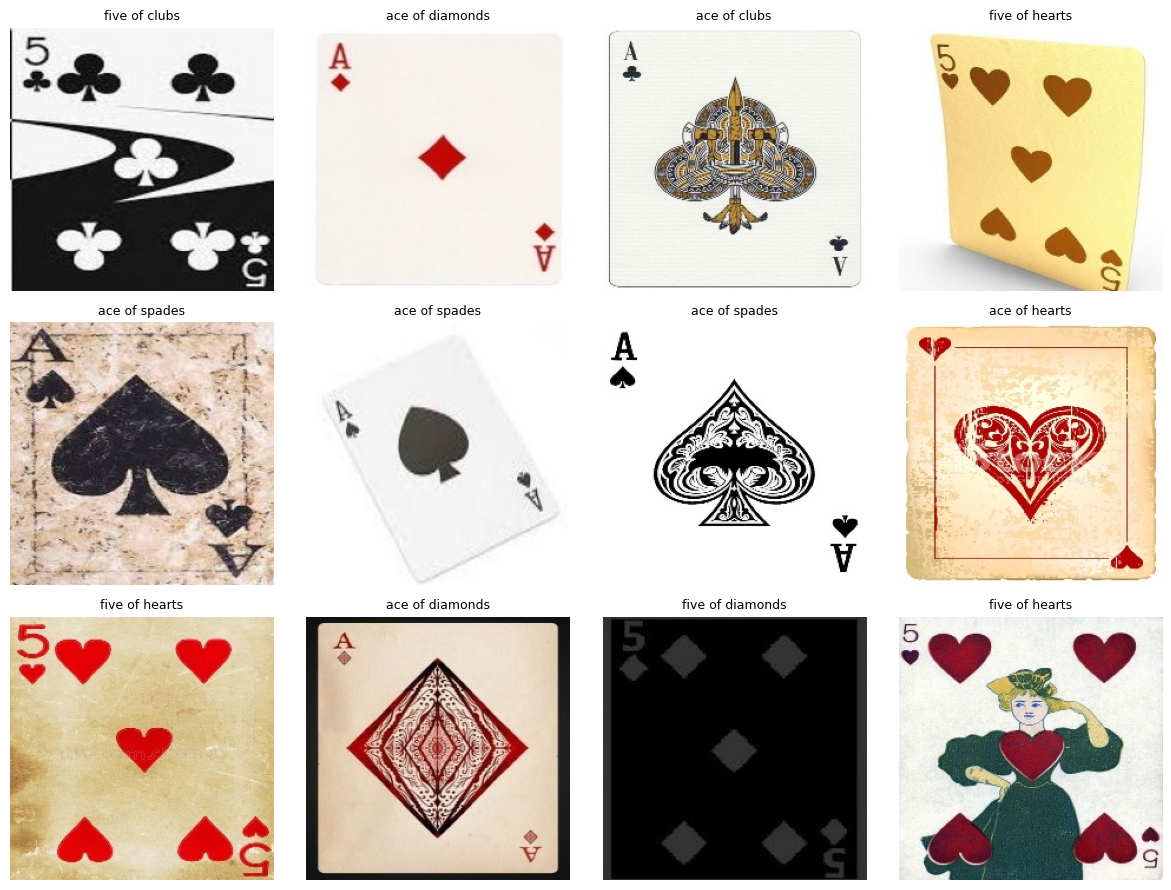

In [57]:

from pathlib import Path
from collections import Counter
from PIL import Image, UnidentifiedImageError
import matplotlib.pyplot as plt
import random

DATASET_DIR = Path.cwd() / "Cards Image Dataset-Classification"
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Find images but exclude notebook checkpoint folders
image_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
    and ".ipynb_checkpoints" not in p.parts
]

# Use the immediate parent folder as the class label
class_counts = Counter(p.parent.name for p in image_files)

print("Total image files:", len(image_files))
print("Number of class folders:", len(class_counts))
print("\nImages per class:")

for label, count in sorted(class_counts.items()):
    print(f"{label}: {count}")

# Display up to 12 randomly selected images
random.seed(42)
samples = random.sample(image_files, min(12, len(image_files)))

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()

for ax, path in zip(axes, samples):
    try:
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(path.parent.name, fontsize=9)
        ax.axis("off")
    except (UnidentifiedImageError, OSError) as error:
        ax.set_title("Unreadable image", fontsize=9)
        ax.axis("off")

for ax in axes[len(samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


Number of classes: 12
Total images: 1767


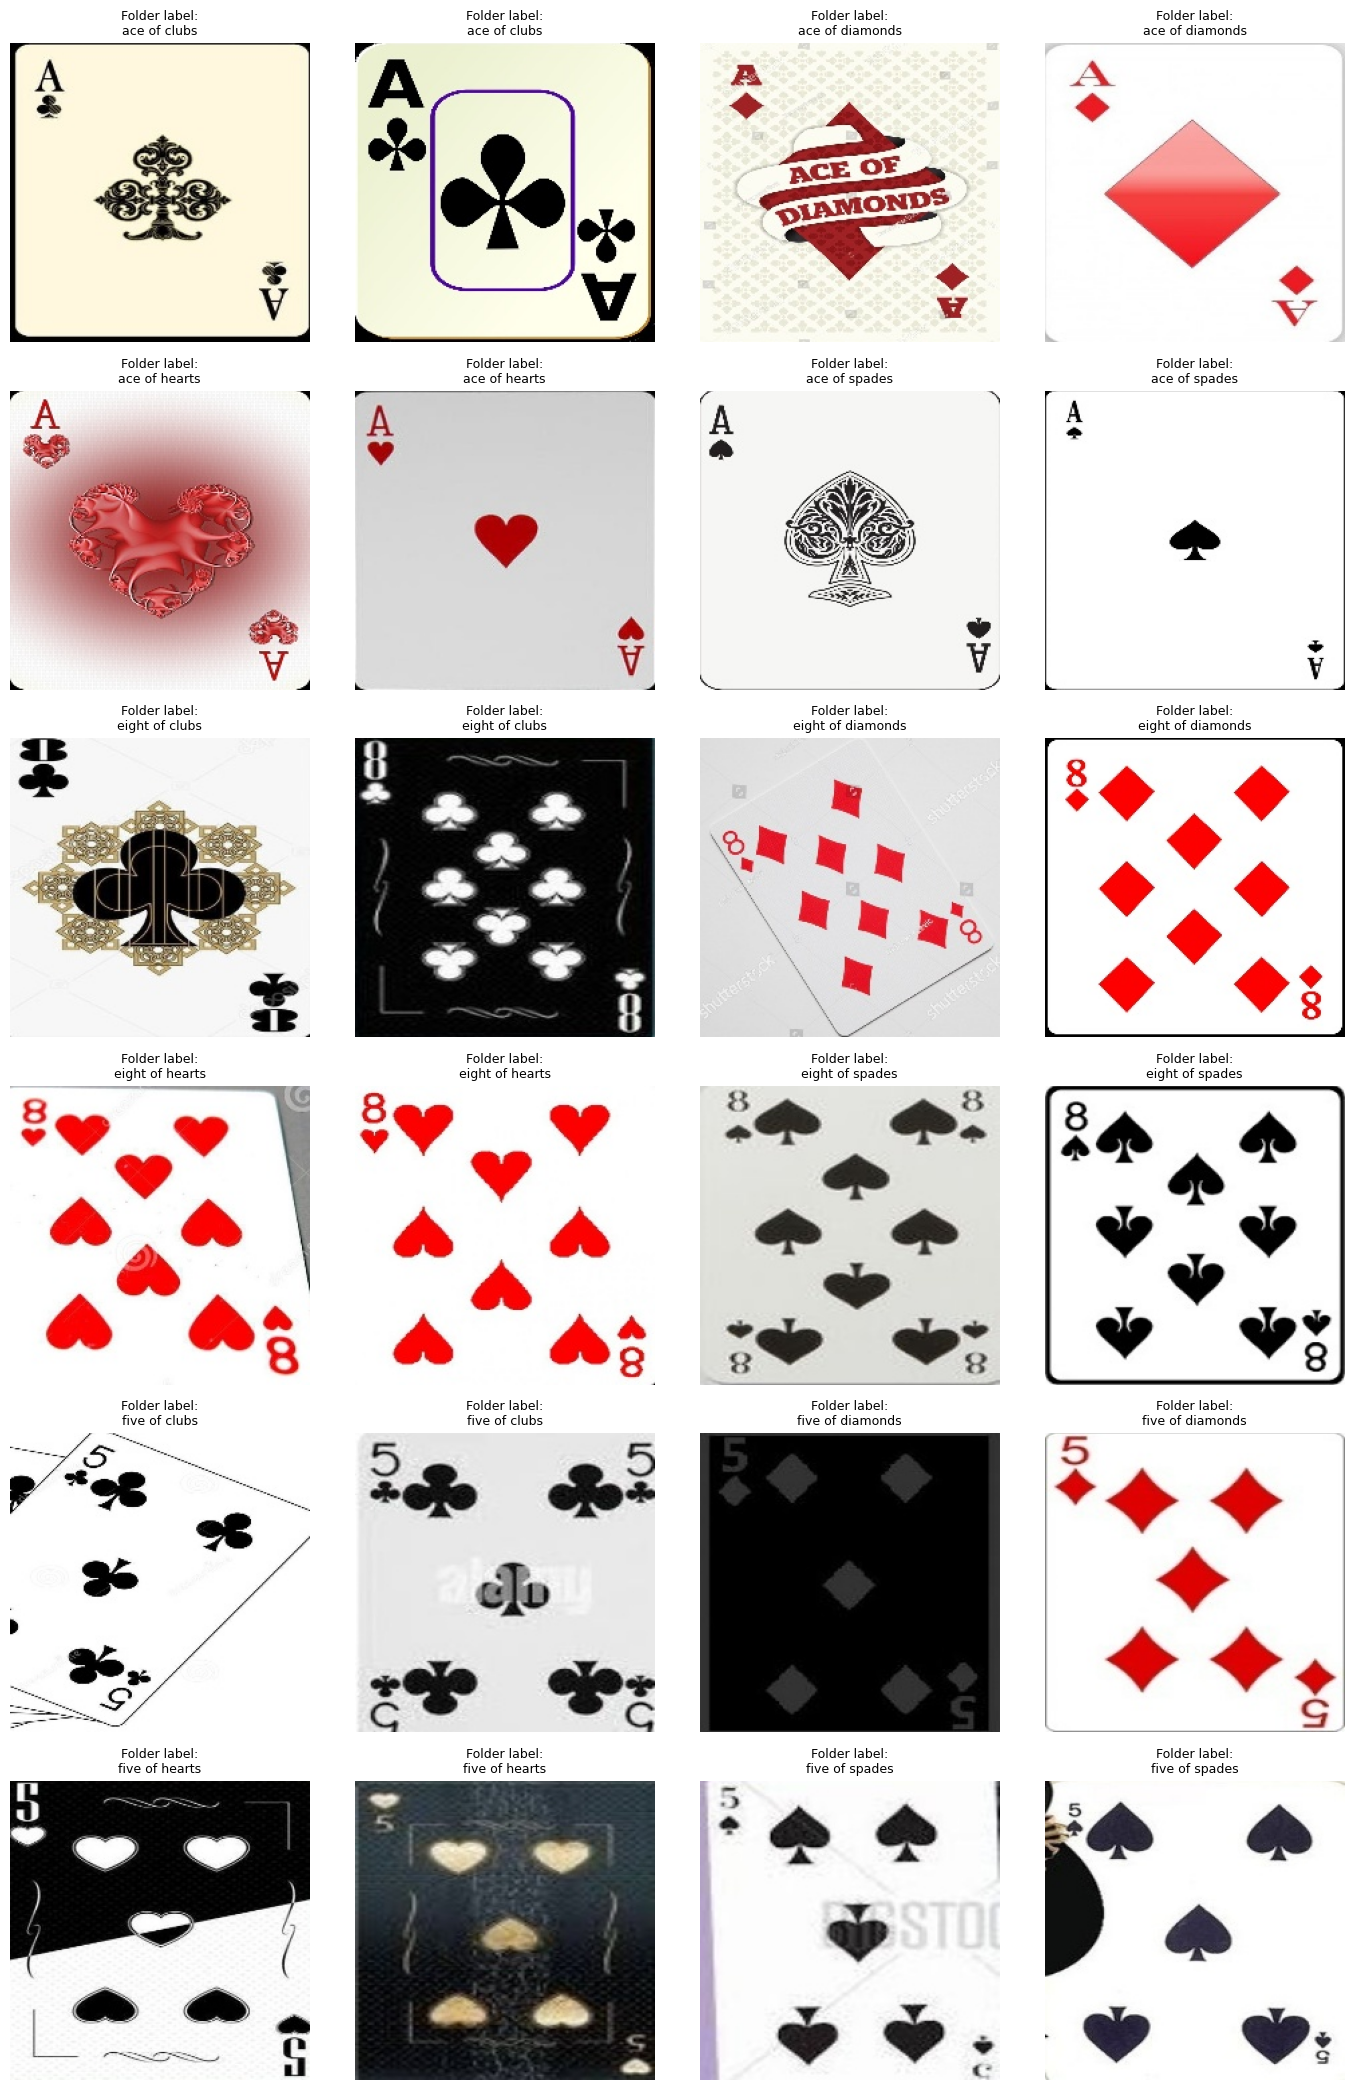

In [58]:

from pathlib import Path
from PIL import Image, UnidentifiedImageError
import matplotlib.pyplot as plt
import random

DATASET_DIR = Path.cwd() / "Cards Image Dataset-Classification"
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
random.seed(42)

# Collect images, excluding hidden/checkpoint folders
class_images = {}

for folder in sorted(DATASET_DIR.iterdir()):
    if not folder.is_dir() or folder.name.startswith("."):
        continue
    if folder.name == ".ipynb_checkpoints" or folder.name == ".ipynb_checkpoints":
        continue

    files = [
        p for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in EXTENSIONS
        and ".ipynb_checkpoints" not in p.parts
    ]

    if files:
        class_images[folder.name] = files

print("Number of classes:", len(class_images))
print("Total images:", sum(len(v) for v in class_images.values()))

# Show up to 2 examples from each class
examples = []
for label, files in class_images.items():
    for path in random.sample(files, min(2, len(files))):
        examples.append((label, path))

columns = 4
rows = (len(examples) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(14, 3.5 * rows))
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax, (label, path) in zip(axes, examples):
    try:
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"Folder label:\n{label}", fontsize=9)
        ax.axis("off")
    except (UnidentifiedImageError, OSError):
        ax.set_title(f"Unreadable:\n{path.name}", fontsize=9)
        ax.axis("off")

for ax in axes[len(examples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [59]:

from PIL import Image, UnidentifiedImageError
from collections import Counter
from pathlib import Path

# Reuse the class_images dictionary from the previous cell
print("Checking image files...")

bad_images = []
image_sizes = Counter()
class_counts = {}

for label, paths in class_images.items():
    valid_count = 0

    for path in paths:
        try:
            with Image.open(path) as img:
                img.verify()

            # Reopen after verify to inspect dimensions
            with Image.open(path) as img:
                image_sizes[img.size] += 1

            valid_count += 1

        except (UnidentifiedImageError, OSError, ValueError) as e:
            bad_images.append((str(path), str(e)))

    class_counts[label] = valid_count

print("\nValid images:", sum(class_counts.values()))
print("Unreadable images:", len(bad_images))

print("\nValid images per class:")
for label, count in sorted(class_counts.items()):
    print(f"{label}: {count}")

print("\nMost common image dimensions:")
for size, count in image_sizes.most_common(10):
    print(f"{size}: {count}")

if bad_images:
    print("\nFirst 10 unreadable files:")
    for path, error in bad_images[:10]:
        print(path, "->", error)


Checking image files...

Valid images: 1767
Unreadable images: 0

Valid images per class:
ace of clubs: 120
ace of diamonds: 129
ace of hearts: 171
ace of spades: 181
eight of clubs: 138
eight of diamonds: 159
eight of hearts: 152
eight of spades: 135
five of clubs: 150
five of diamonds: 138
five of hearts: 136
five of spades: 158

Most common image dimensions:
(224, 224): 1767


In [60]:

import random
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.model_selection import train_test_split
from collections import Counter

# Reuse the class_images dictionary from your previous cells
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Convert image paths and folder names into labeled examples
class_names = sorted(class_images.keys())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

samples = []
for label in class_names:
    for path in class_images[label]:
        samples.append((str(path), class_to_idx[label]))

paths = [p for p, label in samples]
labels = [label for p, label in samples]

train_paths, test_paths, train_labels, test_labels = train_test_split(
    paths,
    labels,
    test_size=0.20,
    random_state=SEED,
    stratify=labels
)

# Convert images into tensors and resize to 128 x 128
image_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

class PlayingCardDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        label = self.labels[index]

        with Image.open(path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

train_dataset = PlayingCardDataset(
    train_paths, train_labels, image_transform
)
test_dataset = PlayingCardDataset(
    test_paths, test_labels, image_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False, num_workers=0
)

print("Classes:", len(class_names))
print("Class names:", class_names)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Total images:", len(train_dataset) + len(test_dataset))

print("\nTraining images per class:")
for label, count in sorted(Counter(train_labels).items()):
    print(f"{class_names[label]}: {count}")

print("\nTesting images per class:")
for label, count in sorted(Counter(test_labels).items()):
    print(f"{class_names[label]}: {count}")

# Check one batch to confirm everything loads correctly
images, targets = next(iter(train_loader))
print("\nBatch image shape:", tuple(images.shape))
print("Batch label shape:", tuple(targets.shape))


Classes: 12
Class names: ['ace of clubs', 'ace of diamonds', 'ace of hearts', 'ace of spades', 'eight of clubs', 'eight of diamonds', 'eight of hearts', 'eight of spades', 'five of clubs', 'five of diamonds', 'five of hearts', 'five of spades']
Training images: 1413
Testing images: 354
Total images: 1767

Training images per class:
ace of clubs: 96
ace of diamonds: 103
ace of hearts: 137
ace of spades: 145
eight of clubs: 110
eight of diamonds: 127
eight of hearts: 122
eight of spades: 108
five of clubs: 120
five of diamonds: 110
five of hearts: 109
five of spades: 126

Testing images per class:
ace of clubs: 24
ace of diamonds: 26
ace of hearts: 34
ace of spades: 36
eight of clubs: 28
eight of diamonds: 32
eight of hearts: 30
eight of spades: 27
five of clubs: 30
five of diamonds: 28
five of hearts: 27
five of spades: 32

Batch image shape: (32, 3, 128, 128)
Batch label shape: (32,)
